In [11]:
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI

load_dotenv()

llm = ChatGoogleGenerativeAI(model="gemini-2.5-flash")

## Parallelization

Parallelization lets independent nodes run at the same time. Here, three nodes each write a post for a different platform, then their results are combined in the shared state. This can save time because no node needs to wait for the others.

In [12]:
from typing import TypedDict

class graph_schema(TypedDict):
    topic: str
    insta: str
    linkedin: str
    twitter: str

#### Create node functions

In [13]:
def create_post_insta(state: graph_schema) -> graph_schema:

    topic = state['topic']

    post = llm.invoke(f"Write an Instagram post about {topic}. Keep the tone casual and engaging.").content
    state['insta'] = post

    return {"insta": post}

def create_post_linkedin(state: graph_schema) -> graph_schema:

    topic = state['topic']

    post = llm.invoke(f"Write a LinkedIn post about {topic}. Keep the tone professional and informative.").content
    state['linkedin'] = post

    return {"linkedin": post}

def create_post_twitter(state: graph_schema) -> graph_schema:

    topic = state['topic']

    post = llm.invoke(f"Write a Twitter post about {topic}. Keep the tone quick and to the point.").content
    state['twitter'] = post

    return {"twitter": post}

#### Create the graph

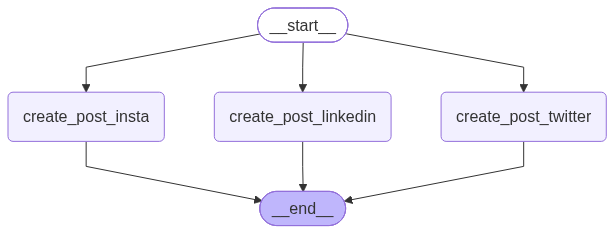

In [14]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)

graph.add_node("create_post_insta", create_post_insta)
graph.add_node("create_post_linkedin", create_post_linkedin)
graph.add_node("create_post_twitter", create_post_twitter)

graph.add_edge(START, "create_post_insta")
graph.add_edge(START, "create_post_linkedin")
graph.add_edge(START, "create_post_twitter")
graph.add_edge("create_post_insta", END)
graph.add_edge("create_post_linkedin", END)
graph.add_edge("create_post_twitter", END)

parallel_graph = graph.compile()

from IPython.display import Image

Image(parallel_graph.get_graph().draw_mermaid_png())

In [15]:
parallel_graph.invoke({"topic": "AI Engineering",
                       "insta": "",
                       "linkedin": "",
                       "twitter": ""
                    })

{'topic': 'AI Engineering',
 'insta': "Here's an Instagram post about AI Engineering, keeping it casual and engaging!\n\n---\n\n**📸 [Image suggestion: Could be a cool graphic with abstract AI elements, a team collaborating around screens, or even a stylized blueprint/circuit board with AI symbols.]**\n\n---\n\n**Caption:**\n\nEver wonder how those smart AI apps actually *work* in the real world? 🤔 Beyond the algorithms and the data, there's a whole crew making the magic happen: AI Engineers! ✨\n\nThink of ML scientists as the chefs creating amazing new recipes 🧑\u200d🍳. AI Engineers? They're building and running the entire kitchen, making sure those delicious dishes get served hot, fresh, and reliably to everyone!\n\nThey're the ones who take brilliant AI models from research and turn them into robust, scalable, and efficient products you use every day. We're talking about:\n*   Building the infrastructure 🏗️\n*   Optimizing performance ⚡\n*   Ensuring data pipelines flow smoothly 🌊\n*